# Spot Modulation and Rotation

Starspots rotating in and out of view make a star's brightness rise and fall on its rotation period: **spot modulation**. TOFFEE has two tools that use this:

- **`spot_mod()`** asks a per-flare question: at the moment each flare went off, was the star's spot-modulation curve near its brightest, its dimmest, or somewhere in between? It fits a double-sine model to the light curve around every flare and reports where in that cycle the flare peak falls.
- **`get_rot_period()`** asks a whole-light-curve question: what *is* the rotation period? It masks out flares and runs a Lomb-Scargle periodogram on what's left.

This notebook runs both on a real, strongly spot-modulated star, and is upfront about where each one is solid and where it needs care: `get_rot_period` in particular turned up two real bugs and a subtler statistical gotcha while this notebook was being built, all covered below.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.timeseries import LombScargle
import lightkurve as lk
import toffee

## 1. Target: AU Mic

AU Mic (TIC 441420236) is a young, rapidly-rotating M dwarf, well known for both a strong, clean rotational modulation and frequent flaring, exactly the combination this notebook needs. Its literature rotation period is **4.836 days**. TESS observed it in sector 27 at 2-minute cadence.

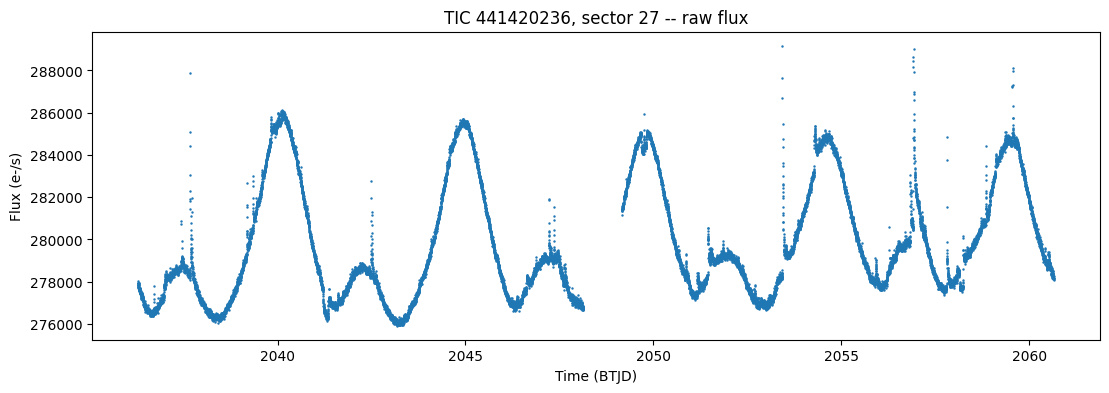

In [2]:
TIC_ID = 441420236
SECTOR = 27

search_result = lk.search_lightcurve(f'TIC {TIC_ID}', mission = 'TESS', author = 'SPOC',
                                     exptime = 120, sector = SECTOR)
lc = search_result.download()

time = np.asarray(lc.time.value, dtype = float)
flux = np.asarray(lc.flux.value, dtype = float)
flux_err = np.asarray(lc.flux_err.value, dtype = float)
finite = np.isfinite(time) & np.isfinite(flux) & np.isfinite(flux_err)
time, flux, flux_err = time[finite], flux[finite], flux_err[finite]

fig, ax = plt.subplots(figsize = (13, 4))
ax.plot(time, flux, '.', ms = 1.5)
ax.set_xlabel('Time (BTJD)')
ax.set_ylabel('Flux (e-/s)')
ax.set_title(f'TIC {TIC_ID}, sector {SECTOR} -- raw flux')
plt.show()

That smooth, repeating double-humped shape (rising and falling by several percent every ~4.8 days, with a second, shallower hump partway through each cycle) is spot modulation, plainly visible even before any detrending. The small sharp upward spikes riding on top of it are flares.

## 2. Detect flares

The usual notebook 1-3 recipe: `flatten()` with a wotan `short_window`, then `detect_flares()`. A `TIC` column is added since some functions later expect one.

In [3]:
orbit_time, lc_quad, lc_wotan, periodic = toffee.flatten(time, flux, flux_err, short_window = 0.25)
quad_flux, quad_flux_err = lc_quad[0], lc_quad[1]
flat_flux, flat_flux_err = lc_wotan[0], lc_wotan[1]
quality = np.zeros(len(orbit_time))

flares = toffee.detect_flares(orbit_time, flat_flux, flat_flux_err, quality)
flares['TIC'] = TIC_ID
print(f'{len(flares)} flares detected')
flares[['T_peak', 'Amplitude', 'Primary_or_Secondary']].head(8)

37 flares detected


,T_peak,Amplitude,Primary_or_Secondary
0,2036.706266,0.004274,primary
1,2037.006275,0.002072,primary
2,2037.443788,0.008054,primary
3,2037.495178,0.001715,primary
4,2037.675739,0.033851,primary
5,2037.720185,0.011219,secondary
6,2039.184116,0.011579,primary
7,2039.349398,0.008123,primary


AU Mic lives up to its reputation: 37 flares in one 24-day sector, several of them overlapping (`secondary`/`tertiary`) pairs, exactly the kind of active star `spot_mod` is meant for.

## 3. Two helpers `spot_mod` uses internally

Both are called by `spot_mod()` for you; they're described here because their argument names reappear inside it, not because you'd normally call them directly.

```python
def make_window_mask(lc_t, lc_flux, lc_errs, flare_peak, window_size):
```

| Argument | Type | Meaning |
|---|---|---|
| `lc_t`, `lc_flux`, `lc_errs` | array | The (quadratic-flattened) light curve |
| `flare_peak` | float | `T_peak` of the flare being examined |
| `window_size` | float | Width of the fitting window, `period_num` rotation cycles wide (set by `spot_mod`) |

Builds three windows around `flare_peak` (centered, and shifted a half-window left and right) and runs a local Lomb-Scargle to confirm a period is actually detectable inside each one. Returns `(ls_mask, window_mask, window_mask_left, window_mask_right, peak_freq, success)`; `success = False` skips the flare rather than fitting a window with no real periodic content.

```python
def spot_fitting(lc_t, lc_flux, lc_errs, flare_mask, init):
```

| Argument | Type | Meaning |
|---|---|---|
| `lc_t`, `lc_flux`, `lc_errs` | array | The light curve |
| `flare_mask` | boolean array | Which points belong to the window being fit (one of `make_window_mask`'s outputs) |
| `init` | array | Initial guess for the 11-parameter quadratic-amplitude double-sine model |

Fits that double-sine model with `scipy.optimize.curve_fit` and returns `(popt, pcov, spot_fit, fail)`; `fail = True` on any fitting exception, including non-convergence.

## 4. `spot_mod()`: where does each flare fall in the spot cycle?

```python
def spot_mod(lc_t, lc_flux, lc_errs, benchmark, plot = False, params = None,
            rand = False, period_num = 3):
```

| Argument | Type | Default | Meaning |
|---|---|---|---|
| `lc_t`, `lc_flux`, `lc_errs` | array | required | The **quadratic-trend-flattened** light curve (`lc_quad` from `flatten()`), not the wotan-flattened one, since wotan's short window would erase the multi-day modulation `spot_mod` is trying to fit |
| `benchmark` | DataFrame | required | A flare table (`detect_flares()` output, or any subset of it) |
| `plot` | bool | `False` | Show a diagnostic figure for every flare fit |
| `params` | N/A | `None` | Unused by the current implementation |
| `rand` | bool | `False` | Unused by the current implementation |
| `period_num` | float | `3` | Width of each fitting window, in rotation cycles |

For every flare, it masks out all flares, finds the global rotation frequency, builds a `period_num`-cycle window around the flare peak (centered, and shifted half a window left/right), fits the double-sine model to each of the three, and reports where the flare peak falls in that cycle: **-1** at the spot-modulation minimum, **+1** at the maximum. Fitting three separate windows and checking they agree on the sign is the safeguard against a fit that happens to look good only because of where exactly the window edges landed.

With `plot = True`, one figure is drawn per flare: for 37 flares that's 37 figures, so here it's run on just the first three as a demonstration before running the full pass quietly.

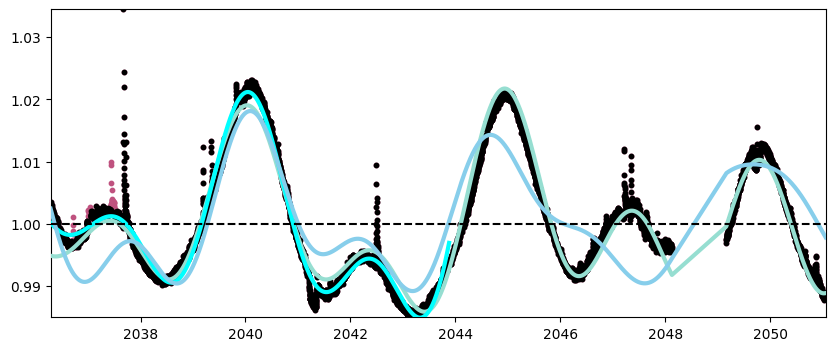

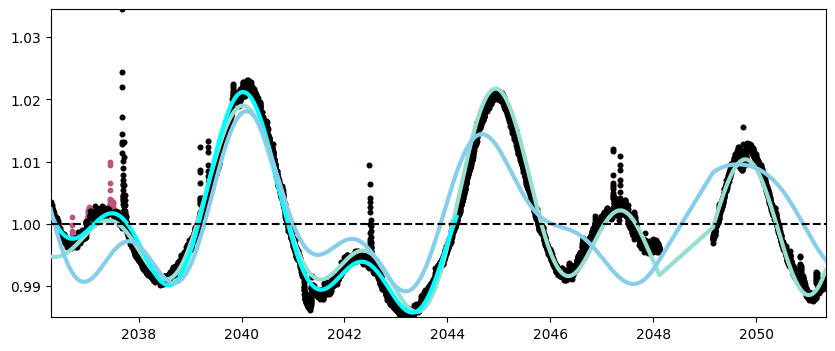

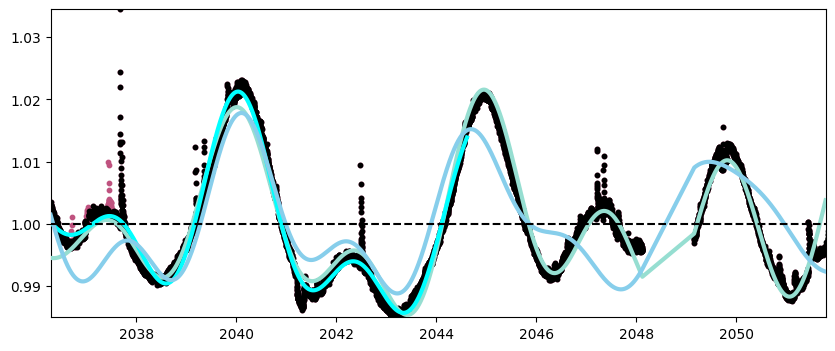

In [4]:
example_flares = flares.iloc[:3]
example_result = toffee.spot_mod(orbit_time, quad_flux, quad_flux_err, example_flares,
                                 plot = True)

Black points are the full masked light curve; magenta points are this flare's centered fitting window. The orange/cyan curves are the fitted center/left-shifted/right-shifted sine models: orange if that window puts the flare above the cycle's midline (closer to a spot maximum), cyan if below.

In [5]:
flare_spot, flare_spot_left, flare_spot_right, red_chi2, spot_exists, spot_agreement = (
    toffee.spot_mod(orbit_time, quad_flux, quad_flux_err, flares, plot = False))

print(f'fits obtained: {np.sum(spot_exists)} / {len(spot_exists)}')
print(f'left/right agreement: {np.sum(spot_agreement)} / {len(spot_agreement)}')

fits obtained: 37 / 37
left/right agreement: 37 / 37


Every one of the 37 flares got a usable fit, and all three windows agreed on the sign for every flare, a sign this star's modulation is clean enough for `spot_mod` to work without the ambiguity flagged in the next section.

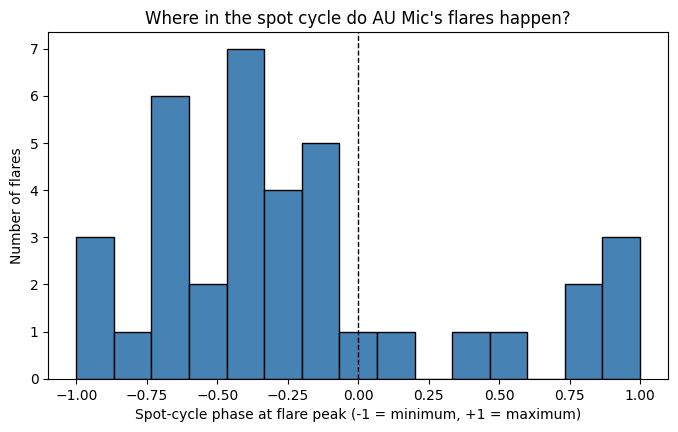

In [6]:
fig, ax = plt.subplots(figsize = (8, 4.5))
ax.hist(flare_spot, bins = 15, range = (-1, 1), color = 'steelblue', edgecolor = 'black')
ax.axvline(0, color = 'black', linestyle = '--', linewidth = 1)
ax.set_xlabel('Spot-cycle phase at flare peak (-1 = minimum, +1 = maximum)')
ax.set_ylabel('Number of flares')
ax.set_title('Where in the spot cycle do AU Mic\'s flares happen?')
plt.show()

More flares land toward the negative side (spot minimum) than the positive side here; with only one sector's worth of flares, though, this is a shape to read qualitatively, the same caution notebooks 5 and 7 raised about small samples. It's exactly the kind of question `spot_mod` exists to let you ask of a larger catalogue: do flares genuinely cluster toward spot maximum, spot minimum, or fall uniformly through the cycle?

## 5. `get_rot_period()`: a global rotation period

```python
def get_rot_period(lc_t, lc_flux, lc_errs, benchmark = None,
                   short_window = 0.25, periodogram = [0.1, 10]):
```

| Argument | Type | Default | Meaning |
|---|---|---|---|
| `lc_t`, `lc_flux`, `lc_errs` | array | required | The **raw** light curve; `flatten()` is called internally |
| `benchmark` | DataFrame or `None` | `None` | Flares to mask out. `None` auto-detects them with default `detect_flares()` settings |
| `short_window` | float | `0.25` | Passed straight to the internal `flatten()` call |
| `periodogram` | list or `None` | `[0.1, 10]` | Passed straight to the internal `flatten()` call |

Runs `flatten()`, masks out flares, and reports the strongest peak of a Lomb-Scargle periodogram (searched over periods 0.1-7 days) as `(period, false_alarm_probability)`.

**Two bugs were found and fixed here while building this notebook** (both logged in `TOFFEE_TWO/CLAUDE.md`): calling it with no `benchmark` crashed outright, because the auto-detection step built its quality-flag array from the length of the raw input rather than the post-`flatten()` length, and the two are essentially never equal once `flatten()` drops any non-finite point. And calling it with `periodogram = None` crashed separately, because `flatten()` returns a 4-tuple in that case and a 5-tuple otherwise, but `get_rot_period` always unpacked 5. Both are now fixed, so every call below actually runs, but fixing the crash is not the same as the answer being right, as the rest of this section shows.

In [7]:
default_period, default_fap = toffee.get_rot_period(time, flux, flux_err, benchmark = flares)
print(f'default call (short_window=0.25, periodogram=[0.1, 10]):')
print(f'  period = {default_period:.4f} days, FAP = {default_fap:.2e}')
print(f'  literature period: 4.836 days')

default call (short_window=0.25, periodogram=[0.1, 10]):
  period = 0.8999 days, FAP = 1.63e-07
  literature period: 4.836 days


Wrong by a factor of five, and reported with a false-alarm probability small enough to look completely trustworthy. This is the design issue already logged in `TOFFEE_TWO/CLAUDE.md` §6 item 5: the default `periodogram = [0.1, 10]` correction actively removes periodicity in that same range, so it partially erases the very rotation signal being searched for, confirmed here on a real, independently-known period rather than an injected one.

The CLAUDE.md entry suggests the fix is to skip the periodogram correction entirely. Now that the crash blocking that option is fixed, here's what actually happens:

In [8]:
no_pgram_period, no_pgram_fap = toffee.get_rot_period(time, flux, flux_err, benchmark = flares,
                                                       periodogram = None)
print(f'periodogram=None call:')
print(f'  period = {no_pgram_period:.4f} days, FAP = {no_pgram_fap:.2e}')
print(f'  literature period: 4.836 days, half of that: {4.836/2:.3f} days')

periodogram=None call:
  period = 2.3818 days, FAP = 1.70e-52
  literature period: 4.836 days, half of that: 2.418 days


Much closer in scale, but not actually right: 2.38 days is almost exactly **half** of 4.836 days. To see why, reproduce the periodogram `get_rot_period` searched (masking flares from the wotan-flattened curve and running the same Lomb-Scargle by hand) and plot the full curve instead of just its single tallest peak.

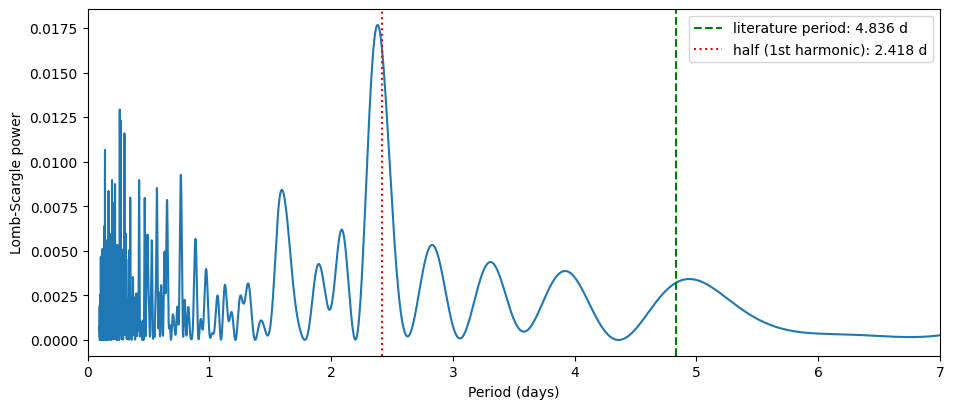

In [9]:
flare_mask = toffee.make_flare_mask(orbit_time, flares)
ls = LombScargle(orbit_time[flare_mask], flat_flux[flare_mask], flat_flux_err[flare_mask])
frequency = np.linspace(1 / 7, 1 / 0.1, 100000)
power = ls.power(frequency)
period_grid = 1 / frequency

fig, ax = plt.subplots(figsize = (11, 4.5))
order = np.argsort(period_grid)
ax.plot(period_grid[order], power[order])
ax.axvline(4.836, color = 'green', linestyle = '--', label = 'literature period: 4.836 d')
ax.axvline(4.836 / 2, color = 'red', linestyle = ':', label = 'half (1st harmonic): 2.418 d')
ax.set_xlim(0, 7)
ax.set_xlabel('Period (days)')
ax.set_ylabel('Lomb-Scargle power')
ax.legend()
plt.show()

There it is: a real, correctly-located peak sits right at the true 4.8-day period, but a taller one sits at half that. AU Mic's light curve has **two** humps per rotation (visible in the very first figure of this notebook, from two active regions at different longitudes), and a plain Lomb-Scargle can't tell that apart from a single symmetric hump repeating twice as often. `get_rot_period` returns only the single tallest peak, so it reports the harmonic.

This is a general Lomb-Scargle limitation, well known in the rotation-period literature, not a TOFFEE-specific bug, and not something a one-line fix resolves, since deciding between a period and its harmonic needs either a shape check (a true single-peaked rotation curve is usually asymmetric between rise and fall; a doubled one tends to look more symmetric) or independent information about the star. The practical lesson: treat `get_rot_period`'s output as a starting point, not a final answer; plot the periodogram (as above) and check whether a comparable peak exists at double the reported period before trusting it.

## Summary

`spot_mod()` worked cleanly out of the box on this target: all 37 flares fit, all three fitting windows agreeing on every one. `get_rot_period()` needed real troubleshooting to even run, and even fixed, its single-peak answer for a real star was wrong twice over in two different ways: erased by the default periodogram correction, and aliased onto a harmonic once that correction was removed. Both failure modes are now understood and logged in `TOFFEE_TWO/CLAUDE.md`; treat any `get_rot_period` result as something to sanity-check against the light curve and its periodogram by eye, not a number to take on faith.